---
tags: [tutorial]
---

# Quantum Teleportation

In this notebook, we use quantum teleportation to learn a minimal set of Qamomile language features.

- Define a quantum program with `@qmc.qkernel`
- Reuse quantum operations by calling one qkernel from another
- Distinguish a `Qubit` from a `Bit` obtained by measurement
- Use a measurement result in a Python `if` statement to write a dynamic quantum circuit
- Transpile to Qiskit and run the circuit with `sample()`

Quantum teleportation is a protocol for transferring the state of a single qubit.

Suppose Alice and Bob share the Bell pair $\frac{|00\rangle+|11\rangle}{\sqrt2}$, and Alice wants to transfer an unknown state $|\psi\rangle=\alpha|0\rangle+\beta|1\rangle$.

Alice performs operations on the state to be transferred and on her half of the Bell pair. She then measures her two qubits and sends the two classical measurement bits to Bob.
Based on the outcome $(m_0,m_1)$ received from Alice, Bob applies $Z^{m_0}X^{m_1}$ to recover $|\psi\rangle$.

Let us use Qamomile to reproduce quantum teleportation as a quantum circuit.

In [1]:
# Install Qamomile and the packages used in this notebook.
# !pip install "qamomile[qiskit,visualization]"

In [2]:
import qamomile.circuit as qmc
from qamomile.qiskit import QiskitTranspiler

## 1. Basic Structure of a Qamomile Program

In Qamomile, the part that constructs a quantum circuit is separate from the part that runs the circuit on a quantum SDK.

- `qamomile.circuit` is an API for writing quantum SDK-independent quantum programs with qubits, gates, measurements, and related operations. In this notebook, we use the short name `qmc`.
- A Python function decorated with `@qmc.qkernel` becomes a **quantum kernel**, or qkernel, that represents a quantum computation. Qamomile analyzes the function body and converts it into a quantum SDK-independent intermediate representation.
- `QiskitTranspiler` converts the quantum kernel into a form that Qiskit can execute.

Qamomile types such as `qmc.Qubit` and `qmc.Bit` are used as annotations for the arguments and return values of a quantum kernel.
Although a quantum kernel looks like an ordinary Python function, its body describes how to construct a quantum circuit.
A `Qubit` represents quantum information before measurement, while a `Bit` represents classical information after measurement. Qamomile treats them as different types.

## 2. Create a Bell Pair

First prepare $H|0\rangle=|+\rangle$ on the first qubit, and then apply a CX gate:

$$
|00\rangle\longmapsto
\frac{|00\rangle+|11\rangle}{\sqrt2}.
$$

If we measure either qubit by itself, 0 and 1 occur at random. However, the two measurement results always agree.
We assume that Alice holds the first qubit of this Bell pair and Bob holds the second.

The following code gives a small example that creates a Bell pair.
A Qamomile `Qubit` is a **handle** that identifies a qubit for use in circuit operations.
A gate consumes the input handle and returns an updated handle for the same qubit.
Because the consumed handle cannot be used in subsequent operations, capture the return value and update the variable, as in `q = qmc.h(q)`.
This follows Qamomile’s **affine type** rule: each qubit handle can be used at most once.

`qmc.qubit("alice")` allocates a qubit initialized in $|0\rangle$.
The string is a name that makes the qubit easy to identify in a circuit diagram. Because `qmc.h` is a single-qubit gate, it returns one updated `Qubit`. Because `qmc.cx` uses both a control and a target, it returns two updated `Qubit` values.

`bell_pair` is a state-preparation qkernel that returns two `Qubit` values before measurement.
By placing the measurements in a separate qkernel, `measure_bell_pair`, we can reuse the prepared Bell pair later in the teleportation circuit.

`qmc.measure(qubit)` measures a qubit in the computational basis and converts it into a classical `qmc.Bit`.
After a value has been measured and has become a `Bit`, quantum gates such as `H` and `CX` cannot be applied to it.
The return annotation of `measure_bell_pair`, `tuple[qmc.Bit, qmc.Bit]`, shows that the execution result contains two measured bits.

In [3]:
@qmc.qkernel
def bell_pair() -> tuple[qmc.Qubit, qmc.Qubit]:
    """Prepare and return a Bell pair without measuring it."""
    alice = qmc.qubit("alice")
    bob = qmc.qubit("bob")
    alice = qmc.h(alice)
    return qmc.cx(alice, bob)


@qmc.qkernel
def measure_bell_pair() -> tuple[qmc.Bit, qmc.Bit]:
    """Prepare a Bell pair and measure both qubits."""
    alice, bob = bell_pair()
    return qmc.measure(alice), qmc.measure(bob)

### Run a Quantum Kernel on Qiskit

`measure_bell_pair` is a quantum SDK-independent quantum program, so defining it does not run it.
Execution has three steps:

1. Instantiate `QiskitTranspiler()`.
2. Use `transpiler.transpile(measure_bell_pair)` to convert the qkernel into an executable program.
3. Use `executable.sample(executor, shots=...)` to run the circuit the specified number of times.

Because transpilation and execution are separate, we can convert the same quantum kernel for different quantum SDKs. We can also run a transpiled parameterized circuit repeatedly with different parameter values.
`transpiler.executor()` creates a Qiskit executor, which we reuse for the remaining circuit.

`sample()` runs a quantum kernel that returns measurement values.
`shots=1024` specifies the number of circuit executions, and `.result()` retrieves the completed result.
Each item in `bell_result.results` is a pair of the form `((bit0, bit1), count)`. It contains one measurement outcome and the number of times that outcome occurred.
In this example, only `00` and `11` appear, and the sum of all `count` values is `1024`.

In [4]:
shots = 1024
transpiler = QiskitTranspiler()
executor = transpiler.executor()

bell_executable = transpiler.transpile(measure_bell_pair)
bell_result = bell_executable.sample(executor, shots=shots).result()
print(bell_result.results)
assert sum(count for _, count in bell_result.results) == shots
assert all(a == b for (a, b), _ in bell_result.results)

[((1, 1), 495), ((0, 0), 529)]


## 3. Use a Measurement Result in an `if` Statement

We now consider teleporting $|+\rangle=H|0\rangle=(|0\rangle+|1\rangle)/\sqrt2$ to Bob.

Alice applies `CX(message, alice)` and `H(message)` to her two qubits, `message` and `alice`.
These operations map the Bell basis to the computational basis. The two measurements that follow are therefore equivalent to a Bell measurement.

`m_message` and `m_alice` are classical `Bit` values that store the measurement results.
These `if` statements are not ordinary Python branches evaluated once on the host.
Instead, they are compiled into dynamic control that runs on the target quantum SDK according to the result of each shot.
In other words, the body of `if m_alice:` does not select a branch in advance in Python. It applies `X` only in shots where the measurement result obtained during circuit execution is 1.
A circuit with this type of mid-circuit branching is called a **dynamic quantum circuit**.
To run such a circuit on hardware, the target device must support mid-circuit measurements and classically controlled gates.

In `teleport_plus_state`, we call `bell_pair()` from the previous section and reuse the Bell-pair preparation.
A qkernel can call another qkernel just like an ordinary Python function can call another function.
Finally, we apply a Hadamard gate to `bob` to map the X basis to the Z basis. If the teleported state is $|+\rangle$, the measurement result is always 0.

`draw()` creates a Qamomile circuit diagram from a quantum kernel.
Before execution, the diagram lets us check the qubit order, the Bell measurement, and the branches controlled by measurement results.
Drawing a circuit does not sample it, so no shot count or executor is required.
`inline=True` expands the body of `bell_pair()`, and `fold_ifs=False` displays the correction gates inside each `if` branch.
Check the X correction controlled by `m_alice` and the Z correction controlled by `m_message`.

In [5]:
@qmc.qkernel
def teleport_plus_state() -> tuple[qmc.Bit, qmc.Bit, qmc.Bit]:
    """Teleport a plus state and measure Bob in the X basis."""
    message = qmc.qubit("message")
    message = qmc.h(message)
    alice, bob = bell_pair()

    message, alice = qmc.cx(message, alice)
    message = qmc.h(message)
    m_message = qmc.measure(message)
    m_alice = qmc.measure(alice)

    if m_alice:
        bob = qmc.x(bob)
    if m_message:
        bob = qmc.z(bob)

    bob = qmc.h(bob)

    return m_message, m_alice, qmc.measure(bob)

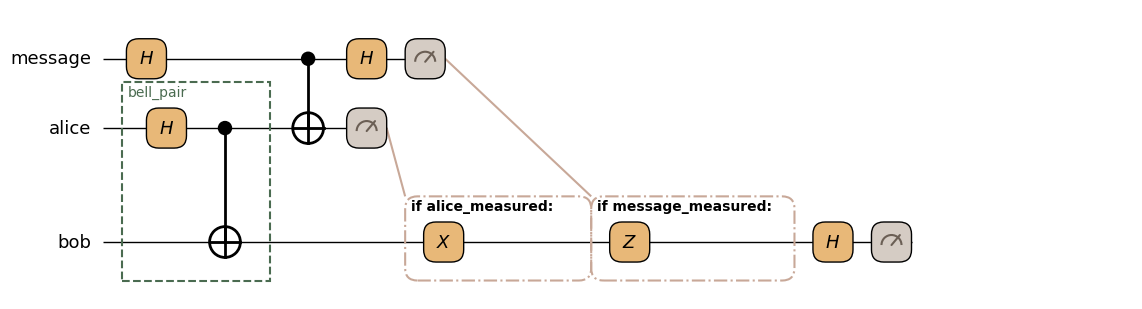

In [6]:
teleport_plus_state.draw(inline=True, fold_ifs=False)

`teleport_plus_state` calls `bell_pair()` and reuses Bell-pair preparation as a qkernel.
Because it returns three `Bit` values, every outcome from `sample()` also has three entries: `(m_message, m_alice, bob)`.

In [7]:
teleport_executable = transpiler.transpile(teleport_plus_state)
teleport_result = teleport_executable.sample(executor, shots=shots).result()

for outcome, count in teleport_result.results:
    print(f"Bell measurement={outcome[:2]}, Bob(X basis)={outcome[2]}: {count}")

assert sum(count for _, count in teleport_result.results) == shots
assert all(bob == 0 for (_, _, bob), _ in teleport_result.results)

Bell measurement=(1, 0), Bob(X basis)=0: 259
Bell measurement=(1, 1), Bob(X basis)=0: 243
Bell measurement=(0, 1), Bob(X basis)=0: 285
Bell measurement=(0, 0), Bob(X basis)=0: 237


Bob's measurement result is always 0, while Alice's measurement results are random.
The information in the teleported quantum state therefore does not appear in the two classical bits alone. Bob can recover the state only by combining the shared Bell pair with the conditional corrections.

## Summary

- Use `@qmc.qkernel` to describe quantum operations.
- Gates return updated qubit handles, so reassign their return values to variables.
- `measure()` returns a classical measurement value of type `Bit`.
- A Python `if` conditioned on a measured `Bit` is converted into dynamic control.
- Reuse quantum operations by calling one qkernel from another.
- Run a quantum kernel that returns measurement values with `sample()`.

Adapted from the [QCE 2026 tutorial](https://github.com/Jij-Inc/Qamomile-QCE2026-Tutorial/blob/main/docs/tutorials/en/01_quantum_teleportation.ipynb).